## Data (SQL)

In [1]:
import pandas as pd

# Load the CSV files into DataFrames
df_courses = pd.read_csv('../data/cursos/plaforedu_schema_prd.courses.csv')
df_competencies = pd.read_csv('../data/cursos/plaforedu_schema_prd.competencies.csv')
df_courses_competencies = pd.read_csv('../data/cursos/plaforedu_schema_prd.courses_competencies.csv')

# Select relevant columns
df_courses = df_courses[['id', 'name', 'description']]
df_competencies = df_competencies[['id', 'name', 'description']]
df_courses_competencies = df_courses_competencies[['id', 'courseId', 'competencyId']]

In [2]:
df_courses.head()

,id,name,description
0,911aa4d6-c3da-471f-a956-39c32df12198,Técnicas de interpretação da Libras,Este curso apresenta o contexto em que se inse...
1,df20012d-ac63-4588-b680-64f83c425c97,Tecnologia Assistiva,Este curso apresenta conceitos relacionados à ...
2,22a619b3-4422-47ae-82a2-b93b5bcbb9f1,Transtorno do Espectro Autista,Este curso apresenta as principais informações...
3,90edcda7-bac3-4010-8ec7-5a7f3c598512,Produção de Vídeos usando OBS Studio e Kdenlive,"O curso aborda de forma objetiva, técnicas e f..."
4,783a5019-643b-47f2-b419-4d87d2cf6f40,Redação científica com tecnologia,"Neste curso, você vai conhecer um pouco sobre ..."


In [3]:
import sqlite3

# Connect to SQLite database (or create it)
conn = sqlite3.connect('../data/plaforedu.db')
cursor = conn.cursor()

# Drop existing tables for a clean start
cursor.execute("DROP TABLE IF EXISTS courses")
cursor.execute("DROP TABLE IF EXISTS competencies")
cursor.execute("DROP TABLE IF EXISTS courses_competencies")

# Create tables
cursor.execute('''
    CREATE TABLE courses (
        id TEXT PRIMARY KEY,
        name TEXT,
        description TEXT
    )
''')

cursor.execute('''
    CREATE TABLE competencies (
        id TEXT PRIMARY KEY,
        name TEXT,
        description TEXT
    )
''')

cursor.execute('''
    CREATE TABLE courses_competencies (
        id TEXT PRIMARY KEY,
        courseId TEXT,
        competencyId TEXT,
        FOREIGN KEY(courseId) REFERENCES courses(id),
        FOREIGN KEY(competencyId) REFERENCES competencies(id)
    )
''')

In [4]:
# Insert data
df_courses.to_sql('courses', conn, if_exists='append', index=False)
df_competencies.to_sql('competencies', conn, if_exists='append', index=False)
df_courses_competencies.to_sql('courses_competencies', conn, if_exists='append', index=False)

conn.commit()
conn.close()

print("Data successfully imported.")

Data successfully imported.


In [5]:
import sqlite3

class PlaforEduDB:
    def __init__(self, db_filepath="../data/plaforedu.db"):
        self.db_filepath = db_filepath
        self.conn = sqlite3.connect(self.db_filepath)
        self.conn.row_factory = sqlite3.Row
        self.cursor = self.conn.cursor()
        print(f"Connected to {self.db_filepath}")

    def execute_query(self, query, params=()):
        try:
            self.cursor.execute(query, params)
            self.conn.commit()
            print("Query executed successfully.")
        except sqlite3.Error as e:
            print(f"An error occurred: {e}")

    def fetch_one(self, query, params=()):
        try:
            self.cursor.execute(query, params)
            row = self.cursor.fetchone()
            return dict(row) if row else None
        except sqlite3.Error as e:
            print(f"An error occurred: {e}")
            return None
    
    def fetch_all(self, query, params=()):
        try:
            self.cursor.execute(query, params)
            rows = self.cursor.fetchall()
            return [dict(row) for row in rows]
        except sqlite3.Error as e:
            print(f"An error occurred: {e}")
            return []

    def get_course(self, course_id):
        query = "SELECT id, name, description FROM courses WHERE id = ?"
        return self.fetch_one(query, (course_id,))

    def get_courses(self):
        query = "SELECT id, name, description FROM courses"
        return self.fetch_all(query)

    def get_competency(self, competency_id):
        query = "SELECT id, name, description FROM competencies WHERE id = ?"
        return self.fetch_one(query, (competency_id,))

    def get_competencies(self):
        query = "SELECT id, name, description FROM competencies"
        return self.fetch_all(query)

    def get_competencies_for_course(self, course_id):
        query = '''
            SELECT c.id, c.name, c.description
            FROM courses_competencies cc
            JOIN competencies c ON cc.competencyId = c.id
            WHERE cc.courseId = ?
        '''
        return self.fetch_all(query, (course_id,))

    def get_courses_for_competency(self, competency_id):
        query = '''
            SELECT co.id, co.name, co.description
            FROM courses_competencies cc
            JOIN courses co ON cc.courseId = co.id
            WHERE cc.competencyId = ?
        '''
        return self.fetch_all(query, (competency_id,))

    def close(self):
        self.conn.close()
        print("Database connection closed.")

In [7]:
# Initialize the class with the database filename
db = PlaforEduDB()

# Fetch all courses
courses = db.fetch_all("SELECT * FROM courses")

for course in courses[:5]:
    print(course)
    print()

Connected to ../data/plaforedu.db
{'id': '911aa4d6-c3da-471f-a956-39c32df12198', 'name': 'Técnicas de interpretação da Libras', 'description': 'Este curso apresenta o contexto em que se insere a interpretação da Libras e do Português nos Estudos da Tradução, trazendo conhecimentos teóricos e exemplos práticos da área. Você terá a possibilidade de analisar o uso das técnicas de interpretação, as escolhas tradutórias e o trabalho em dupla a partir de uma reflexão sobre as especificidades do campo para resolver dificuldades e problemas de tradução/interpretação da Libras.'}

{'id': 'df20012d-ac63-4588-b680-64f83c425c97', 'name': 'Tecnologia Assistiva', 'description': 'Este curso apresenta conceitos relacionados à Tecnologia Assistiva, com o intuito de favorecer a compreensão dessa área enquanto um importante apoio para o processo de inclusão escolar dos alunos com deficiência e com necessidades educacionais especiais.'}

{'id': '22a619b3-4422-47ae-82a2-b93b5bcbb9f1', 'name': 'Transtorno d

In [8]:
competencies = db.get_competencies_for_course("269e37f1-dcc3-46b1-b912-06c5ba5acfbf")
for competency in competencies:
    print(f"ID: {competency['id']}")
    print(f"Competency: {competency['name']}")
    print(f"Description: {competency['description']}")
    print()

ID: 4c081af1-b613-4465-b989-2a4b09d76e0e
Competency: Gestão para resultados
Description: Domínio dos conhecimentos sobre gestão, inerentes à capacidade de tomar decisões e gerenciar de forma\ncompetente e estratégica os atos da organização. Capacidade de atuar com base em desempenho, metas,\nresultados e impactos, construídos de forma aderente ao contexto organizacional e social existente.

ID: 1c596a8d-dff3-46ca-a684-8eb59b20800c
Competency: Liderança eficaz
Description: Dirigir equipes, otimizando a aplicação de talentos disponíveis e criando um ambiente positivo e comprometido para a obtenção de resultados.



In [9]:
cid = "bf6ee8ab-b64b-48fb-ad5a-738548fc2302"

competency = db.get_competency(cid)
print(f"Competency: {competency['name']}")
print(f"{competency['description']}")
print()
print('--------')
print()

courses = db.get_courses_for_competency(cid)
for course in courses:
    print(f"{course['id']}")
    print(f"# {course['name']}")
    print(course['description'])
    print()

Competency: Diferenciação e personalização
Usar tecnologias digitais para atender às diversas necessidades de aprendizagem dos aprendentes, permitindo que estes progridam a diferentes níveis e velocidades e sigam caminhos e objetivos de aprendizagem individuais.

--------

175ca57b-0ba9-445f-b60a-b9f628980515
# A invisibilidade da mulher negra no contexto acadêmico
Promover a formação sobre relações étnico-raciais no Brasil, no contexto das Comissões de Heteroidentificação e justifica-se pela orientação legal da Portaria Normativa nº 4, de 06 de abril de 2018, que regulamenta o procedimento complementar à autodeclaração dos candidatos negros (pretos e pardos), para fins de preenchimento das vagas reservadas para concurso público.\n\nModalidade: curso do tipo autoinstrucional apoiado por videoaulas (não serão disponibilizados outros materiais).

e4a58e87-5332-4337-9c77-bd3ec2546d4d
# A valorização da cultura afro-brasileira na sala de aula
Promover a formação sobre relações étnico-racia

<BarContainer object of 69 artists>

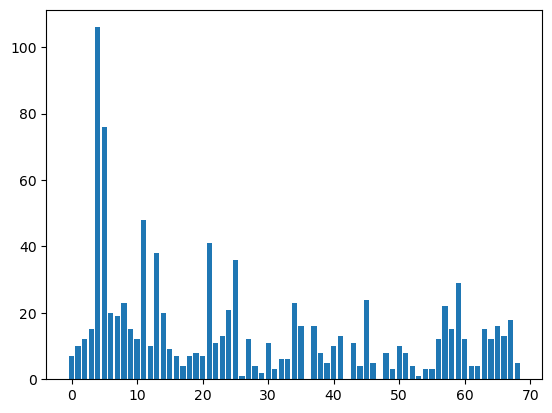

In [28]:
import numpy as np
import matplotlib.pyplot as plt

all_courses_num = []

for competency in competencies:
    comp_courses = db.get_courses_for_competency(competency['id'])
    all_courses_num.append(len(comp_courses))

plt.bar(range(len(all_courses_num)), all_courses_num)

## Graph

In [10]:
import os
from typing import Annotated, Literal
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from IPython.display import Image, display

from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import SystemMessage, AIMessage, ToolMessage, HumanMessage, AnyMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode

In [11]:
llm = ChatOpenAI(model="gpt-4o-mini")

In [31]:
class State(TypedDict):
    objective: str
    competency_id: str
    competency: str
    available_courses: list[dict]
    selected_courses: list[dict]
    evaluation: str
    evaluation_feedback: str

In [23]:
def format_competencies(competencies):
    formated = ""
    for c in competencies:
        formated_competency = f"ID: {c['id']}\nNome: {c['name']}\nDescrição: {c['description']}\n\n"
        formated += formated_competency
    return formated

competencies = db.get_competencies()
# print(format_competencies(competencies))

In [112]:
CONTEXT_PROMPT = """<context>O PlaforEdu é um sistema curadoria de cursos para formação continuada de servidores da rede pública. Trilhas são percursos formativos propostos a partir do encadeamento de cursos ordenados, com o objetivo de desenvolver uma determinada competência com um determinado objetivo.</context>\n\n"""


FILTER_COURSES_PROMPT = """# Instruções #
Você é um especialista em curadoria de cursos para estruturação de trilhas formativas. Seu objetivo é desenvolver estas trilhas de acordo com os cursos disponíveis e um objetivo fornecido.

# Informações #
- Considere que a plataforma onde os cursos estão cadastrados está organizada em itinerários formativos. 
- Cada itinerário  formativo possui um determinado número de competências associadas. 
- Cada competência possui um descritor específico, que expressa os conhecimentos, habilidades e atitudes que serão desenvolvidos. 
- Cada competência gera uma trilha formativa.
- Considere que as trilhas são percursos formativos propostos a partir do encadeamento de cursos ordenados, com o objetivo de desenvolver a competência contemplada naquela Trilha.
- O descritor de cada competência expressa o objetivo da Trilha formativa.
- Você deve identificar e avaliar cursos que atendam às demandas de capacitação, formação ou atualização, no ambiente da plataforma, apenas com o seguinte objetivo.
- Organize os cursos na ordem que achar mais adequada para atender ao objetivo proposto.

# Objetivo #
{objective}

# Cursos Disponíveis #
{available_courses}
"""


EVALUATE_COURSES_PROMPT = """# Instruções #
Você é um avaliador em curadoria de cursos para estruturação de trilhas formativas.

# Regras #
- A trilha deverá estar de acordo com o objetivo proposto.
- A trilha deverá ter pelo menos 3 cursos.

# Objetivo #
{objective}

# Cursos Selecionados #
{selected_courses}
"""

In [113]:
def select_courses(state: State):
    competency = db.get_competency(state['competency_id'])
    courses = db.get_courses_for_competency(state['competency_id'])
    return {
        "competency": f"{competency['name']}: ({competency['description']})",
        "available_courses": courses
    }

In [114]:
class Course(BaseModel):
    id: str = Field(
        description="O ID do curso."
    )
    name: str = Field(
        description="O nome do curso."
    )
    justification: str = Field(
        description="Justificativa para a seleção do curso."
    )
    # description: str = Field(
    #     description="A descrição do curso."
    # )

class Courses(BaseModel):
    courses: list[Course] = Field(
        description="A lista de cursos disponíveis."
    )
    # justification: str = Field(
    #     description="Justificativa para a seleção dos cursos."
    # )


def filter_courses(state: State):
    system_prompt = CONTEXT_PROMPT + FILTER_COURSES_PROMPT
    if "evaluation_feedback" in state:
        if len(state["evaluation_feedback"]) > 1:
            system_prompt += f"\n# Feedback #\n{state['evaluation_feedback']}"

    courses_prompt = ChatPromptTemplate.from_template(system_prompt)
    courses_chain = courses_prompt | llm.with_structured_output(Courses)
    response = courses_chain.invoke({
        "objective": state["objective"],
        "available_courses": state["available_courses"],
    })
    return {
        "selected_courses": response.courses
    }

In [115]:
class Evaluation(BaseModel):
    result: Literal["Bom", "Ruim"] = Field(
        description="O resultado da avaliação. Poderá ser 'Bom' ou 'Ruim'."
    )
    feedback: str = Field(
        default="",
        description="O feedback da geração da trilha que será usado para corrigir os possíveis problemas."
    )

def evaluate_courses(state: State):
    evaluate_prompt = ChatPromptTemplate.from_template(CONTEXT_PROMPT + EVALUATE_COURSES_PROMPT)
    evaluate_chain = evaluate_prompt | llm.with_structured_output(Evaluation)
    response = evaluate_chain.invoke({
        "objective": state["objective"],
        "selected_courses": state["selected_courses"],
    })
    return {
        "evaluation": response.result,
        "evaluation_feedback": response.feedback
    }

In [116]:
def route_courses(state: State):
    if state["evaluation"] == "Ruim" and "evaluation_feedback" in state:
        return "redo"
    else:
        return "end"

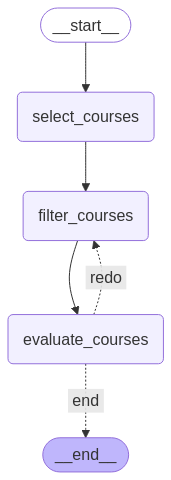

In [117]:
workflow = StateGraph(State)

# Nodes
workflow.add_node("select_courses", select_courses)
workflow.add_node("filter_courses", filter_courses)
workflow.add_node("evaluate_courses", evaluate_courses)

# Edges
workflow.add_edge(START, "select_courses")
workflow.add_edge("select_courses", "filter_courses")
workflow.add_edge("filter_courses", "evaluate_courses")
workflow.add_conditional_edges(
    "evaluate_courses",
    route_courses,
    {
        "redo": "filter_courses",
        "end": END
    }
)

graph = workflow.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [122]:
for c in competencies:
    print(f"{c['name']} - ({c['id']})")

Colaboração profissional - (179ee2c7-90c8-4f00-8cc0-02f63a056062)
Prática reflexiva - (30db1816-b75d-4364-855e-f1d09b0b6016)
Desenvolvimento Profissional Contínuo (DPC) digital - (74347817-89b5-47e7-9c5d-6c07c69690fa)
Seleção - (bb6db702-1fd8-40b5-abeb-e067768c5def)
Ensino - (e4f31519-2fad-4fe8-b476-5da4715a16e9)
Orientação - (3062277b-4218-4f2b-8645-90ba3651fc52)
Aprendizagem colaborativa - (5a036b8e-1546-48ea-a616-2890f9904d4c)
Aprendizagem autorregulada - (b64634ab-e0ca-42a8-a95d-b8670598488b)
Estratégias de avaliação - (30521bbb-e702-47d7-a287-b242cf5bf600)
Feedback e planificação - (c6d771e2-d2a0-443d-b615-b0c813965e99)
Análise de evidências - (12052eae-22a2-44ce-a8ff-07f5b5a8f816)
Acessibilidade e inclusão - (161fd267-d68a-4f88-925c-8082f17fb8b2)
Gestão, proteção e partilha - (93a78bdb-6f5f-4a1a-a012-82eb8b9db4d8)
Diferenciação e personalização - (bf6ee8ab-b64b-48fb-ad5a-738548fc2302)
Envolvimento ativo - (fa3b0d3e-857f-4d3b-839d-3d06a726a986)
Literacia da informação e das mídias

In [125]:
for c in db.get_courses_for_competency("e4f31519-2fad-4fe8-b476-5da4715a16e9"):
    print(f"{c['name']}")

Ambientes Digitais de Aprendizagem
Temos que dar aulas remotas... E agora?
Software de Apresentação
Educação Especial e Inclusão
Educação Inclusiva: Introdução ao Transtorno do Espectro Autista (TEA)
Ensino e Aprendizagem: Teorias, Métodos e Avaliação
Boas Práticas de Segurança do Trabalho em Laboratórios
Comunicação Oral e Escrita
Aprendizagem Organizacional e Trilhas de Aprendizagem
Gamificação para a Educação
Wiki: produção colaborativa de conhecimento
Videoaula: da concepção à postagem
Inovações em Tecnologia Educacional
Design Thinking Aplicado à Educação
Aprendizagem Significativa
Qualidade de Cursos em Educação a Distância
Didática
Pesquisa em Sala de Aula na Educação Básica
Projetos Educacionais e Interdisciplinares
Estratégias Flexíveis de Ensino em Tempos de Pandemia
Inclusão Sociodigital para Multiplicadores
Educador Maker: ensino 'mão na massa'
Moodle para Educadores
Educador Maker: Aprendizagem Baseada em Projetos
Acessibilidade e Tecnologia
Ferramentas Digitais para Cur

In [126]:
import pprint

inputs = {
    "competency_id": "e4f31519-2fad-4fe8-b476-5da4715a16e9",
    "objective": "Aprimorar estratégias de ensino"
}

for output in graph.stream(inputs):
    for key, value in output.items():
        pprint.pprint(f"Output from node '{key}':")
        pprint.pprint('---')
        pprint.pprint(value, indent=2, width=80, depth=None)
    pprint.pprint('---')

"Output from node 'select_courses':"
'---'
{ 'available_courses': [ { 'description': 'O Curso tem por objetivo apresentar '
                                          'as principais características, '
                                          'funcionalidades e limitações '
                                          'existentes nos ambientes digitais '
                                          'de aprendizagem - AVA, contribuindo '
                                          'para a tomada de decisão tanto para '
                                          'a escolha do AVA mais adequado '
                                          'quanto para escolhas de desenho '
                                          'instrucional.',
                           'id': '1175549d-9719-4349-a765-9ca8130aeb6e',
                           'name': 'Ambientes Digitais de Aprendizagem'},
                         { 'description': 'As aulas presenciais estão '
                                          'suspensas e